<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<div style="text-align: center; margin-bottom: 10px;">
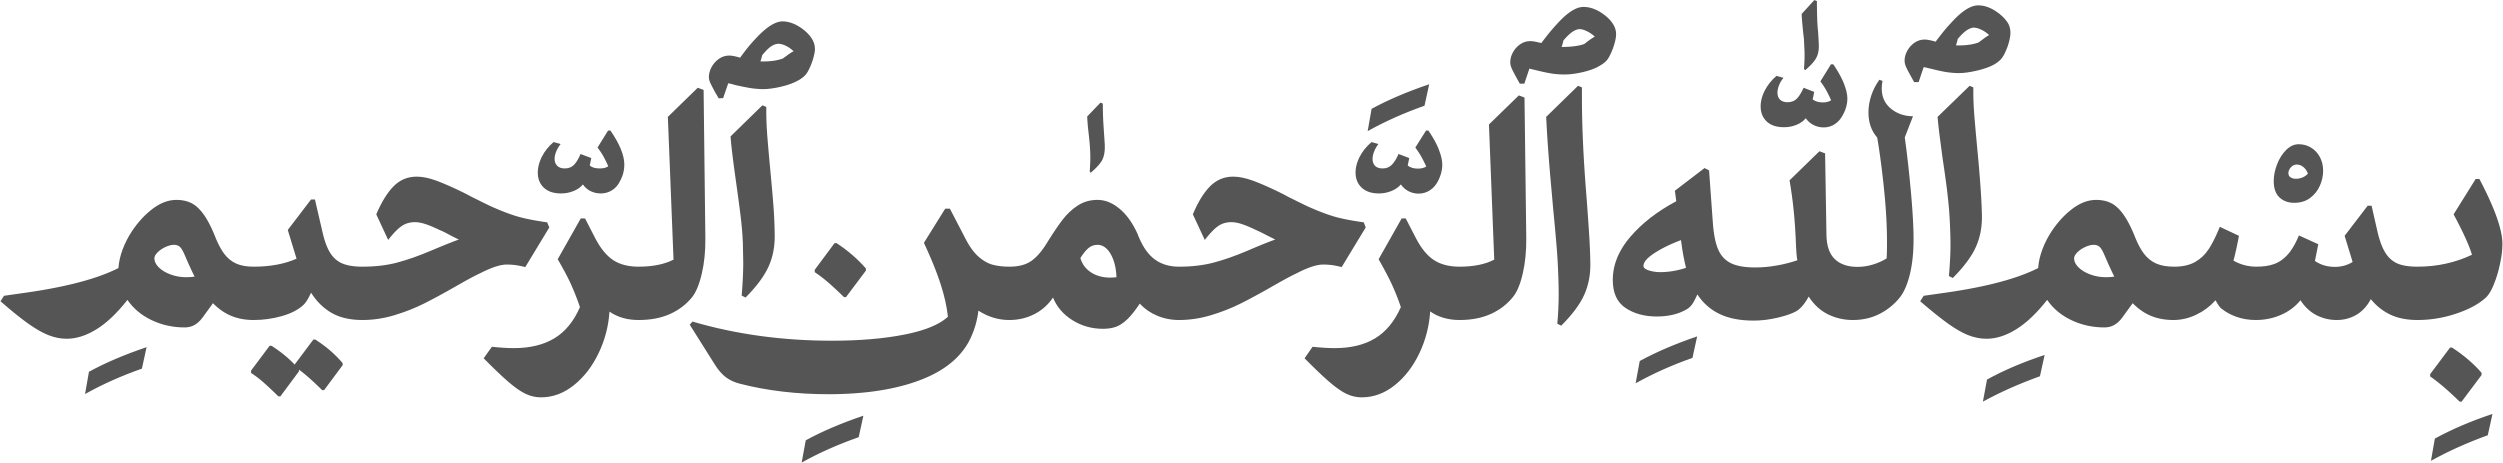
<div style="margin-top: 18px; display: flex; justify-content: center; align-items: center; gap: 30px;">
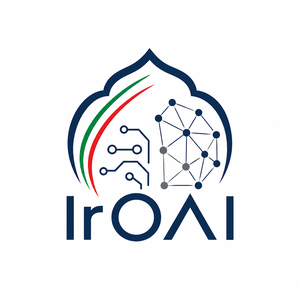
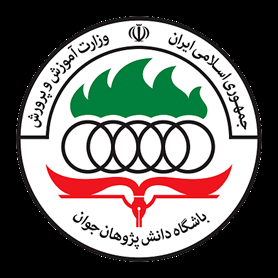
</div>
</div>
<h1 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">تمرین عملی المپیاد هوش مصنوعی — دوره دوم (۱۴۰۴-۱۴۰۵)</h1>
<h2 style="text-align: right;color: #3498db;">تفسیرپذیری جامع: Grad-CAM و ترفند شباهت پچ در CNN و Vision Transformer و CLIP</h2>
<p style="text-align: right;"><b>موضوع:</b> هوش مصنوعی تفسیرپذیر (XAI) — مقایسه CNN ،ViT و مدل‌های چندوجهی CLIP (گرادیانی در برابر بدون گرادیان)</p>
<p style="text-align: right;color: var(--jp-ui-font-color2, #6b7280);">این یک تمرین آموزشی جامع است؛ هدف، درک عمیق ریاضی، پیاده‌سازی Grad-CAM روی CNN و ViT و CLIP، و مقایسه با روش بدون گرادیان Patch Similarity است.</p>
</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">مقدمه و چشم‌انداز جامع (Overview & Theoretical Foundations)</h2>
<p style="text-align: right;">درک تصمیم‌گیری مدل‌های یادگیری عمیق یکی از ارکان اساسی هوش مصنوعی قابل اعتماد (Trustworthy AI) است. در این دفترچه جامع، روش‌های انتساب ویژگی (Feature Attribution) را در سه افق معماری مدرن مقایسه می‌کنیم:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>شبکه‌های عصبی پیچشی (CNN)</b> مانند ResNet-18 بر پایه سوگیری استقرایی مکانی (Spatial Inductive Bias).</li>
<li style="text-align: right;"><b>ترنسفورمرهای بینایی (Vision Transformers / ViT)</b> بر پایه مکانیزم خودتوجهی (Self-Attention) روی توکن‌های پچ.</li>
<li style="text-align: right;"><b>مدل‌های چندوجهی زبان-تصویر (CLIP)</b> در دو گونه ViT و CNN با هدایت پرامپت‌های متنی بدون سرپرست (Zero-Shot Text Queries).</li>
<li style="text-align: right;"><b>ترفند شباهت پچ (Patch Similarity Trick)</b> به عنوان یک روش مستقیم، سریع و بدون نیاز به گرادیان (Gradient-Free).</li>
</ol>
<h3 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">فرمول‌بندی ریاضی الگوریتم Grad-CAM</h3>
<p style="text-align: right;">فرض کنید $A^k$ نقشه فعال‌سازی کانال $k$ در لایه هدف و $y^c$ امتیاز کلاس هدف $c$ باشد. وزن‌های اهمیت کانال $\alpha_k^c$ با میانگین‌گیری مکانی (GAP) گرادیان‌ها محاسبه می‌شوند:</p>
$$\alpha_k^c = \frac{1}{Z} \sum_{i=1}^U \sum_{j=1}^V \frac{\partial y^c}{\partial A_{i, j}^k}$$
<p style="text-align: right;">سپس نقشه حرارتی از ترکیب خطی با وزن‌ها و اعمال تابع $\text{ReLU}$ حاصل می‌گردد:</p>
$$L_{\text{Grad-CAM}}^c = \text{ReLU}\left( \sum_k \alpha_k^c A^k \right)$$

</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">بحث کنید ۱: چرایی انتخاب لاجیت‌ها و نقش رلو (Why Logits & ReLU?)</h3>
<p style="text-align: right;">در فرمول‌بندی ریاضی Grad-CAM دو تصمیم طراحی بسیار مهم و کلیدی وجود دارد:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>چرا گرادیان را نسبت به نمره لاجیت ($y^c$) محاسبه می‌کنیم و نه احتمال خروجی سافت‌مکس ($P(c)$)؟</b></li>
<li style="text-align: right;"><b>چرا در انتهای محاسبه نقشه حرارتی از تابع $\text{ReLU}$ استفاده می‌شود؟</b></li>
</ol>
<details style="text-align: right;">
<summary style="text-align: right;color: #3498db;cursor: pointer;"><b>مشاهده تحلیل و پاسخ تفصیلی</b></summary>
<p style="text-align: right;"><b>پاسخ به سوال ۱:</b> تابع Softmax تمامی لاجیت‌ها را به یکدیگر وابسته می‌کند: $P(c) = \frac{e^{y^c}}{\sum_j e^{y^j}}$. گرادیان $\frac{\partial P(c)}{\partial A}$ شامل مؤلفه‌های منفی از سایر کلاس‌ها می‌شود و در مواردی که شبکه با اطمینان بسیار بالا پیش‌بینی می‌کند (اشباع سافت‌مکس)، گرادیان به سمت صفر میل می‌کند (Gradient Vanishing). در نتیجه، گرادیان نسبت به لاجیت $y^c$ نمایانگر خالص‌ترین و مستقیم‌ترین شواهد درون شبکه برای حضور کلاس $c$ بدون مداخله سایر کلاس‌ها است.</p>
<p style="text-align: right;"><b>پاسخ به سوال ۲:</b> هدف ما برجسته‌سازی ویژگی‌هایی از تصویر است که تاثیر <i>مثبت</i> روی حضور کلاس $c$ داشته‌اند. مقادیر منفی در ترکیب خطی نشان‌دهنده ویژگی‌هایی هستند که متعلق به دسته‌های دیگر بوده یا حضور کلاس $c$ را تضعیف می‌کنند. اعمال $\text{ReLU}$ پیکسل‌هایی با شواهد منفی را حذف کرده و تمرکز را صرفاً روی ویژگی‌های تاییدکننده می‌گذارد.</p>
</details>

</div>

In [1]:
# Setup - read-only cell; do not edit
import os
import sys
import copy
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms

import timm
import open_clip

# Set reproducible seeds
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")


Using compute device: cpu


In [2]:
# Data & Models Initialization - read-only cell; do not edit
# 1. Load ResNet-18 (CNN benchmark)
model_resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).to(device).eval()

# 2. Standard ImageNet Preprocessing
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Load ImageNet class names
with open('imagenet_classes.txt', 'r', encoding='utf-8') as f:
    categories = [line.strip() for line in f.readlines()]

# 4. Load multi-class test image (dog & cat)
img_both_pil = Image.open('images/both.png').convert('RGB')
input_tensor_cnn = preprocess(img_both_pil).unsqueeze(0).to(device)

print(f"ImageNet categories loaded: {len(categories)}")
print(f"Input image size: {img_both_pil.size}")


ImageNet categories loaded: 1000
Input image size: (224, 224)


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش اول: سازوکار ثبت Hook در PyTorch</h2>
<p style="text-align: right;">برای استخراج فعال‌سازی‌های پیش‌رو و گرادیان‌های پس‌انتشار یک لایه دلخواه، از مکانیزم <b>Hook</b> در PyTorch استفاده می‌کنیم:</p>
<ul style="text-align: right;">
<li style="text-align: right;"><code>register_forward_hook</code>: ثبت نقشه فعال‌سازی $A^k$ حین عبور رو به جلو.</li>
<li style="text-align: right;"><code>register_full_backward_hook</code>: ثبت گرادیان $\nabla_{A^k} y^c$ حین پس‌انتشار معکوس.</li>
</ul>
<p style="text-align: right;"><b>تسک ۱:</b> کلاس <code>GradCAM</code> را پیاده‌سازی کنید تا امکان استخراج و آزادسازی امن هوک‌ها فراهم شود.</p>

</div>

In [3]:
class GradCAM:
    """
    General Grad-CAM implementation using PyTorch forward and backward hooks.
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.hooks = []
        self._register_hooks()

    def _forward_hook(self, module, input, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def _register_hooks(self):
        h1 = self.target_layer.register_forward_hook(self._forward_hook)
        h2 = self.target_layer.register_full_backward_hook(self._backward_hook)
        self.hooks.extend([h1, h2])

    def remove_hooks(self):
        for h in self.hooks:
            h.remove()
        self.hooks = []


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش دوم: تولید نقشه حرارتی و هم‌پوشانی (Colormap Overlay)</h2>
<p style="text-align: right;">در متد <code>generate_cam_cnn</code>، پس از پس‌انتشار روی لاجیت هدف، میانگین مکانی گرادیان‌ها محاسبه شده، ترکیب خطی با نقشه‌ها صورت گرفته و با $\text{ReLU}$ مقادیر مثبت فیلتر می‌شوند. سپس تابع <code>overlay_cam_on_image</code> نقشه را با پالت رنگی Jet رنگ‌آمیزی کرده و با تصویر ورودی تلفیق می‌کند:</p>
$$\text{Overlay} = \alpha \cdot \text{Image} + (1 - \alpha) \cdot \text{Heatmap}$$
<p style="text-align: right;"><b>تسک ۲:</b> توابع <code>generate_cam_cnn</code> و <code>overlay_cam_on_image</code> را تکمیل کنید.</p>

</div>

In [4]:
def generate_cam_cnn(gradcam_obj, input_tensor, target_class=None):
    """
    Computes normalized Grad-CAM heatmap for a CNN layer.
    """
    gradcam_obj.model.zero_grad()
    logits = gradcam_obj.model(input_tensor)
    if target_class is None:
        target_class = logits.argmax(dim=1).item()
        
    score = logits[0, target_class]
    score.backward()
    
    weights = gradcam_obj.gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.sum(weights * gradcam_obj.activations, dim=1, keepdim=True)
    cam = F.relu(cam).squeeze().cpu().numpy()
    
    cam_min, cam_max = cam.min(), cam.max()
    if cam_max > cam_min:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = np.zeros_like(cam)
        
    return cam, target_class, score.item()

def overlay_cam_on_image(img_pil, cam_map, alpha=0.5):
    """
    Resizes CAM map, applies JET colormap, and blends with input image.
    """
    img_resized = np.array(img_pil.resize((224, 224)), dtype=np.float32) / 255.0
    cam_resized = cv2.resize(cam_map, (224, 224))
    cam_uint8 = np.uint8(255 * cam_resized)
    heatmap_bgr = cv2.applyColorMap(cam_uint8, cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap_bgr, cv2.COLOR_BGR2RGB) / 255.0
    blended = alpha * img_resized + (1.0 - alpha) * heatmap_rgb
    blended = np.uint8(255 * (blended / np.max(blended)))
    return blended, np.uint8(255 * heatmap_rgb)


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش سوم: تفکیک‌پذیری کلاسی و تحلیل فرسایش لایه‌ای در CNN</h2>
<p style="text-align: right;">در تصویر <code>both.png</code> هر دو حیوان سگ و گربه حضور دارند. مدل پیش‌بینی‌های برتر را انجام داده و Grad-CAM برای هر دو کلاس به صورت مجزا استخراج می‌شود.</p>
<p style="text-align: right;"><b>تسک ۳:</b> کد زیر را اجرا کرده تا تفکیک‌پذیری کلاسی و رفتار لایه‌های مختلف ResNet-18 مقایسه شود.</p>

</div>

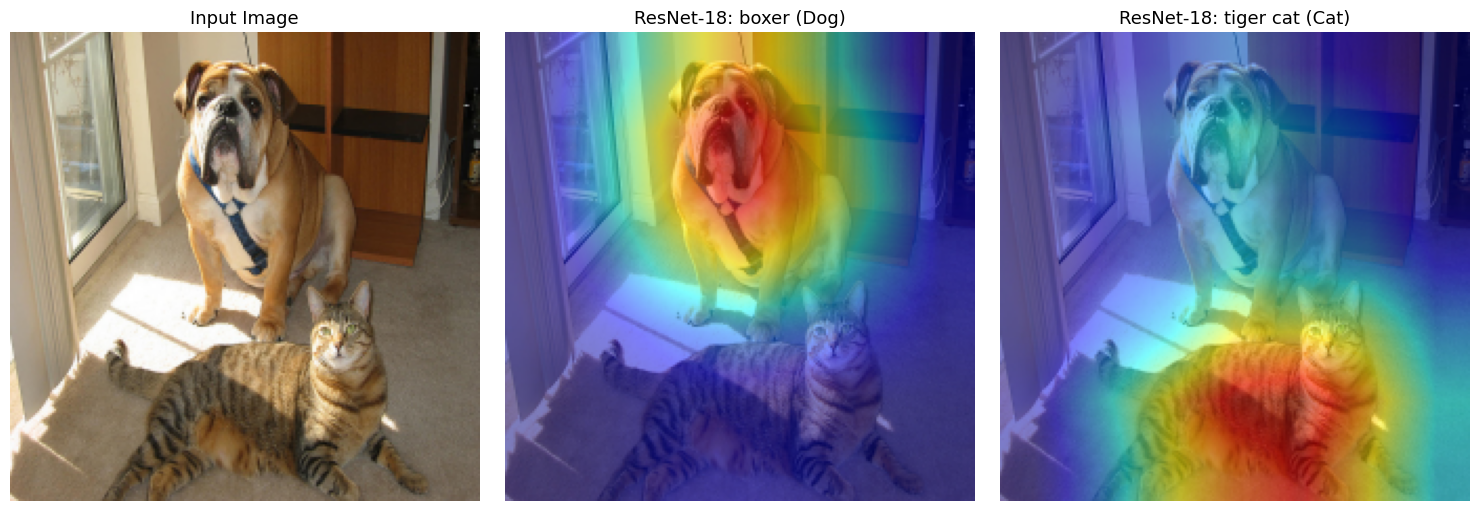

In [5]:
# Execute CNN Class Discrimination on ResNet-18
cam_cnn = GradCAM(model_resnet, model_resnet.layer4)
dog_idx = 242  # boxer
cat_idx = 282  # tiger cat

cam_dog_cnn, _, score_dog_cnn = generate_cam_cnn(cam_cnn, input_tensor_cnn, target_class=dog_idx)
overlay_dog_cnn, _ = overlay_cam_on_image(img_both_pil, cam_dog_cnn, alpha=0.5)

cam_cat_cnn, _, score_cat_cnn = generate_cam_cnn(cam_cnn, input_tensor_cnn, target_class=cat_idx)
overlay_cat_cnn, _ = overlay_cam_on_image(img_both_pil, cam_cat_cnn, alpha=0.5)
cam_cnn.remove_hooks()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_both_pil.resize((224, 224)))
axes[0].set_title("Input Image", fontsize=13)
axes[0].axis('off')

axes[1].imshow(overlay_dog_cnn)
axes[1].set_title(f"ResNet-18: {categories[dog_idx]} (Dog)", fontsize=13)
axes[1].axis('off')

axes[2].imshow(overlay_cat_cnn)
axes[2].set_title(f"ResNet-18: {categories[cat_idx]} (Cat)", fontsize=13)
axes[2].axis('off')
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش چهارم: الگوریتم Grad-CAM روی Vision Transformer (ViT)</h2>
<p style="text-align: right;">اعمال Grad-CAM روی ترنسفورمرهای بینایی دارای تفاوت ساختاری اساسی با شبکه‌های کانولوشنال است:</p>
<ul style="text-align: right;">
<li style="text-align: right;">تصویر به $N = (H/P) \times (W/P)$ پچ تقسیم شده و با یک توکن کلاسی <code>[CLS]</code> به دنباله‌ای با طول $1 + N$ تبدیل می‌شود. برای یک تصویر ۲۲۴×۲۲۴ با اندازه پچ ۱۶، تعداد پچ‌ها $14 \times 14 = 196$ است.</li>
<li style="text-align: right;">اکتیویشن‌ها و گرادیان‌ها در بلوک‌های ترنسفورمر دارای فرم تنسور $(B, 1 + N, D)$ هستند.</li>
<li style="text-align: right;">برای اعمال Grad-CAM، توکن <code>[CLS]</code> در اندیس صفر را کنار می‌گذاریم و $N$ توکن باقیمانده را به یک شبکه دوبعدی فضایی $(B, D, 14, 14)$ بازآرایی (Reshape) می‌کنیم.</li>
<li style="text-align: right;">سپس میانگین‌گیری مکانی گرادیان‌ها و ترکیب خطی مشابه CNN اجرا می‌شود.</li>
</ul>
<p style="text-align: right;"><b>تسک ۴:</b> تابع <code>generate_cam_vit</code> را برای مدل سبک <code>vit_tiny_patch16_224</code> پیاده‌سازی و اجرا کنید.</p>

</div>

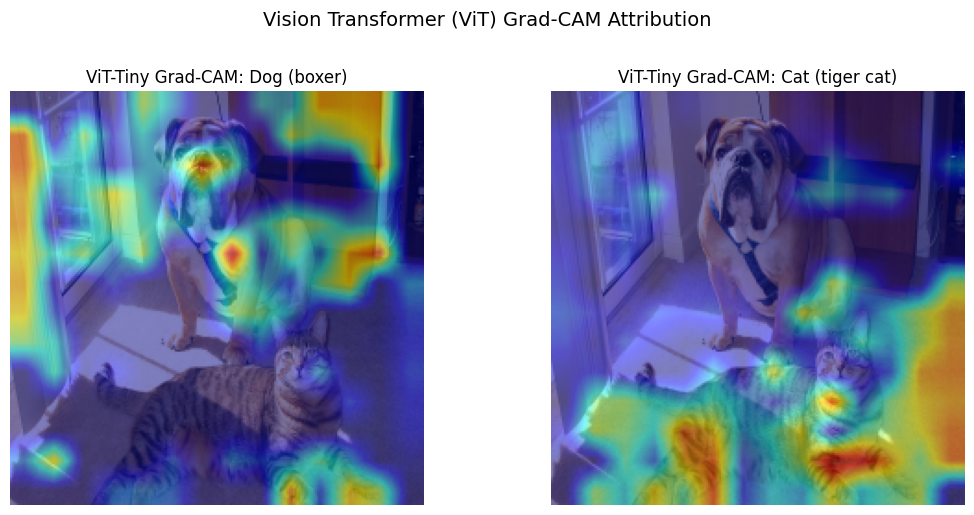

In [6]:
# Load lightweight Vision Transformer: vit_tiny_patch16_224
model_vit = timm.create_model('vit_tiny_patch16_224', pretrained=True).to(device).eval()

def generate_cam_vit(model, target_layer, input_tensor, target_class=None):
    """
    Computes Grad-CAM for Vision Transformer by reshaping patch tokens to 2D grid.
    """
    activations, gradients = None, None
    def f_hook(m, i, o):
        nonlocal activations
        activations = o.detach()
    def b_hook(m, gi, go):
        nonlocal gradients
        gradients = go[0].detach()
        
    h1 = target_layer.register_forward_hook(f_hook)
    h2 = target_layer.register_full_backward_hook(b_hook)
    
    model.zero_grad()
    logits = model(input_tensor)
    if target_class is None:
        target_class = logits.argmax(dim=1).item()
        
    score = logits[0, target_class]
    score.backward()
    h1.remove(); h2.remove()
    
    # Exclude [CLS] token at index 0: shape (1, 196, D)
    patch_acts = activations[:, 1:, :].permute(0, 2, 1).view(1, -1, 14, 14)
    patch_grads = gradients[:, 1:, :].permute(0, 2, 1).view(1, -1, 14, 14)
    
    # GAP weights over 14x14 spatial dimensions
    weights = patch_grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * patch_acts).sum(dim=1)).squeeze().cpu().numpy()
    
    cam_min, cam_max = cam.min(), cam.max()
    if cam_max > cam_min:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = np.zeros_like(cam)
        
    return cam, target_class, score.item(), activations

# Run ViT Grad-CAM on both.png for Dog (242) and Cat (282)
target_layer_vit = model_vit.blocks[-1].norm1
cam_dog_vit, _, score_dog_vit, acts_dog_vit = generate_cam_vit(model_vit, target_layer_vit, input_tensor_cnn, dog_idx)
overlay_dog_vit, _ = overlay_cam_on_image(img_both_pil, cam_dog_vit, alpha=0.5)

cam_cat_vit, _, score_cat_vit, acts_cat_vit = generate_cam_vit(model_vit, target_layer_vit, input_tensor_cnn, cat_idx)
overlay_cat_vit, _ = overlay_cam_on_image(img_both_pil, cam_cat_vit, alpha=0.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(overlay_dog_vit)
axes[0].set_title(f"ViT-Tiny Grad-CAM: Dog ({categories[dog_idx]})", fontsize=12)
axes[0].axis('off')

axes[1].imshow(overlay_cat_vit)
axes[1].set_title(f"ViT-Tiny Grad-CAM: Cat ({categories[cat_idx]})", fontsize=12)
axes[1].axis('off')
plt.suptitle("Vision Transformer (ViT) Grad-CAM Attribution", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش پنجم: ترفند شباهت پچ برای تبیین بصری (The Patch Similarity Trick)</h2>
<p style="text-align: right;">در شبکه‌های ترنسفورمر، هر پچ تصویری مستقیماً به یک بردار ویژگی $z_i \in \mathbb{R}^D$ در فضای نهان تبدیل می‌شود. یک روش بسیار جذاب، سریع و <b>کاملاً بدون نیاز به گرادیان (Gradient-Free)</b>، محاسبه شباهت کسینوسی میان بردار هر پچ و یک بردار پرسش (Query Vector) است:</p>
<ul style="text-align: right;">
<li style="text-align: right;"><b>در ViT استاندارد:</b> بردار وزن‌های کلاس مربوطه در سر دسته‌بندی نهایی $W_c = \text{head.weight}[c] \in \mathbb{R}^D$ به عنوان کوئری استفاده می‌شود:
$$S_i = \frac{z_i \cdot W_c}{\|z_i\| \|W_c\|}$$</li>
<li style="text-align: right;">سپس بردارهای شباهت به ابعاد شبکه پچ‌ها ($14 \times 14$) بازآرایی و نرمال‌سازی می‌شوند.</li>
</ul>
<p style="text-align: right;"><b>تسک ۵:</b> تابع <code>compute_patch_similarity_vit</code> را پیاده‌سازی کرده و نقشه حاصل را مستقیماً با نقشه Grad-CAM در کنار هم مقایسه کنید.</p>

</div>

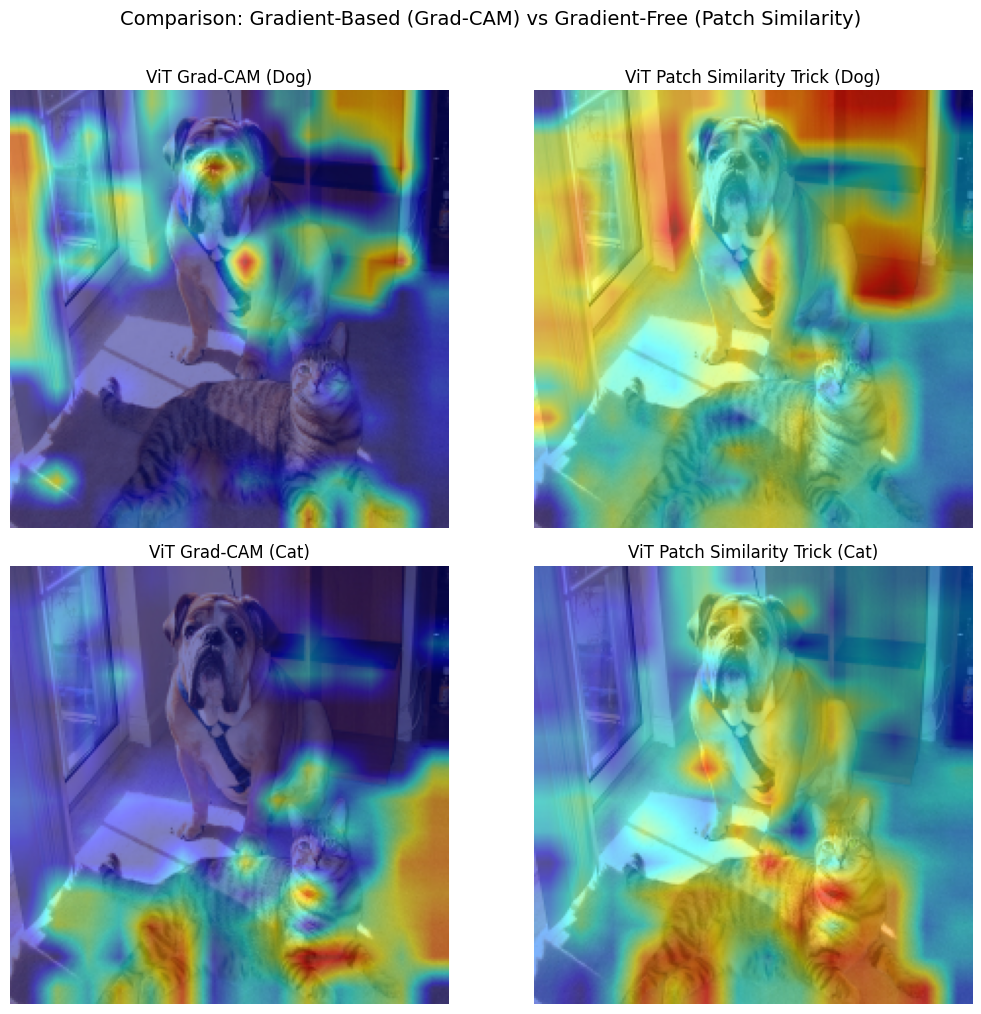

In [7]:
def compute_patch_similarity_vit(model, input_tensor, target_class):
    """
    Gradient-Free attribution via cosine similarity between patch tokens and class weights.
    """
    tokens = None
    def hook_fn(m, i, o):
        nonlocal tokens
        tokens = o.detach()
        
    hook = model.blocks[-1].norm1.register_forward_hook(hook_fn)
    with torch.no_grad():
        model(input_tensor)
    hook.remove()
    
    # Extract spatial patch tokens (excluding [CLS] token)
    patch_tokens = tokens[0, 1:, :]  # (196, D)
    class_weight = model.head.weight[target_class].detach()  # (D,)
    
    # Cosine similarity between each patch and class weight vector
    sim = F.cosine_similarity(patch_tokens, class_weight.unsqueeze(0), dim=1)
    sim = sim.view(14, 14).cpu().numpy()
    
    sim_min, sim_max = sim.min(), sim.max()
    sim_norm = (sim - sim_min) / (sim_max - sim_min + 1e-8)
    return sim_norm

# Compute Patch Similarity for Dog and Cat
sim_dog_vit = compute_patch_similarity_vit(model_vit, input_tensor_cnn, dog_idx)
overlay_sim_dog, _ = overlay_cam_on_image(img_both_pil, sim_dog_vit, alpha=0.5)

sim_cat_vit = compute_patch_similarity_vit(model_vit, input_tensor_cnn, cat_idx)
overlay_sim_cat, _ = overlay_cam_on_image(img_both_pil, sim_cat_vit, alpha=0.5)

# Visual Comparison: Grad-CAM vs Patch Similarity Trick
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes[0, 0].imshow(overlay_dog_vit)
axes[0, 0].set_title("ViT Grad-CAM (Dog)", fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(overlay_sim_dog)
axes[0, 1].set_title("ViT Patch Similarity Trick (Dog)", fontsize=12)
axes[0, 1].axis('off')

axes[1, 0].imshow(overlay_cat_vit)
axes[1, 0].set_title("ViT Grad-CAM (Cat)", fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(overlay_sim_cat)
axes[1, 1].set_title("ViT Patch Similarity Trick (Cat)", fontsize=12)
axes[1, 1].axis('off')

plt.suptitle("Comparison: Gradient-Based (Grad-CAM) vs Gradient-Free (Patch Similarity)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">بحث کنید ۲: مقایسه روش گرادیانی Grad-CAM و ترفند بدون گرادیان Patch Similarity</h3>
<p style="text-align: right;">به تصاویر مقایسه‌ای تسک ۵ دقت کنید. هر دو روش توانسته‌اند موقعیت تقریبی حیوانات را مشخص کنند، اما تفاوت‌های مفهومی مهمی دارند:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>چه مزیت محاسباتی برای ترفند Patch Similarity نسبت به Grad-CAM وجود دارد؟</b></li>
<li style="text-align: right;"><b>چه عواملی ممکن است باعث ایجاد نویز یا خطای پس‌زمینه در روش Patch Similarity شوند که Grad-CAM از آن مصون است؟</b></li>
</ol>
<details style="text-align: right;">
<summary style="text-align: right;color: #3498db;cursor: pointer;"><b>مشاهده تحلیل و پاسخ تفصیلی</b></summary>
<p style="text-align: right;"><b>پاسخ به سوال ۱:</b> روش Patch Similarity کاملاً بدون نیاز به گرادیان (Gradient-Free) است و تنها با یک فوروارد ساده محاسبه می‌شود. بنابراین در سیستم‌های Real-time یا دستگاه‌های لبه که حافظه یا قابلیت پس‌انتشار ندارند، بسیار سریع‌تر و کم‌مصرف‌تر است.</p>
<p style="text-align: right;"><b>پاسخ به سوال ۲:</b> روش شباهت پچ تنها هندسه فضای برداری لایه نهایی را می‌سنجد. در ترنسفورمرها پدیده‌ای موسوم به «سینک‌های توجه» (Attention Sinks) یا توکن‌های رجیستر پس‌زمینه وجود دارد که ممکن است به دلیل نرمال‌سازی بالا، شباهت بالایی با بردار هدف نشان دهند. در مقابل، Grad-CAM اثر تعاملی لایه‌های قبل را از طریق مسیر پس‌انتشار گرادیان فیلتر کرده و تنها پچ‌هایی را هایلایت می‌کند که واقعاً در نمره نهایی نقش مثبت داشته‌اند.</p>
</details>

</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش ششم: تبیین با پرامپت متنی در CLIP ViT (Grad-CAM و Patch Similarity)</h2>
<p style="text-align: right;">مدل‌های چندوجهی <b>CLIP</b> تصویر و متن را در یک فضای تعبیه‌سازی مشترک (Shared Embedding Space) نگاشت می‌کنند. این قابلیت امکان تبیین نامحدود با زبان طبیعی (Open-Vocabulary Attribution) را فراهم می‌سازد:</p>
<ul style="text-align: right;">
<li style="text-align: right;">امتیاز شباهت متن-تصویر $y = \cos(I_{\text{embed}}, T_{\text{embed}}) \cdot 100$ به عنوان متغیر هدف گرادیان در نظر گرفته می‌شود.</li>
<li style="text-align: right;"><b>در CLIP ViT Grad-CAM:</b> گرادیان نسبت به توکن‌های آخرین بلوک ترنسفورمر بینایی گرفته شده و به صورت $(7, 7)$ بازآرایی می‌شود.</li>
<li style="text-align: right;"><b>در CLIP Patch Similarity:</b> هر توکن پچ از طریق ماتریس پروجکشن تصویری <code>visual.proj</code> به فضای متنی نگاشت شده و شباهت کسینوسی مستقیم آن با بردار تعبیه متن پرامپت (مثلاً <code>"a photo of a dog"</code>) سنجیده می‌شود!</li>
</ul>
<p style="text-align: right;"><b>تسک ۶:</b> هر دو روش را روی مدل <code>open_clip ViT-B-32</code> با پرامپت‌های متنی سگ و گربه اجرا و مقایسه نمایید.</p>

</div>

C:\Users\01\AppData\Local\Programs\Python\Python39\lib\site-packages\open_clip\factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


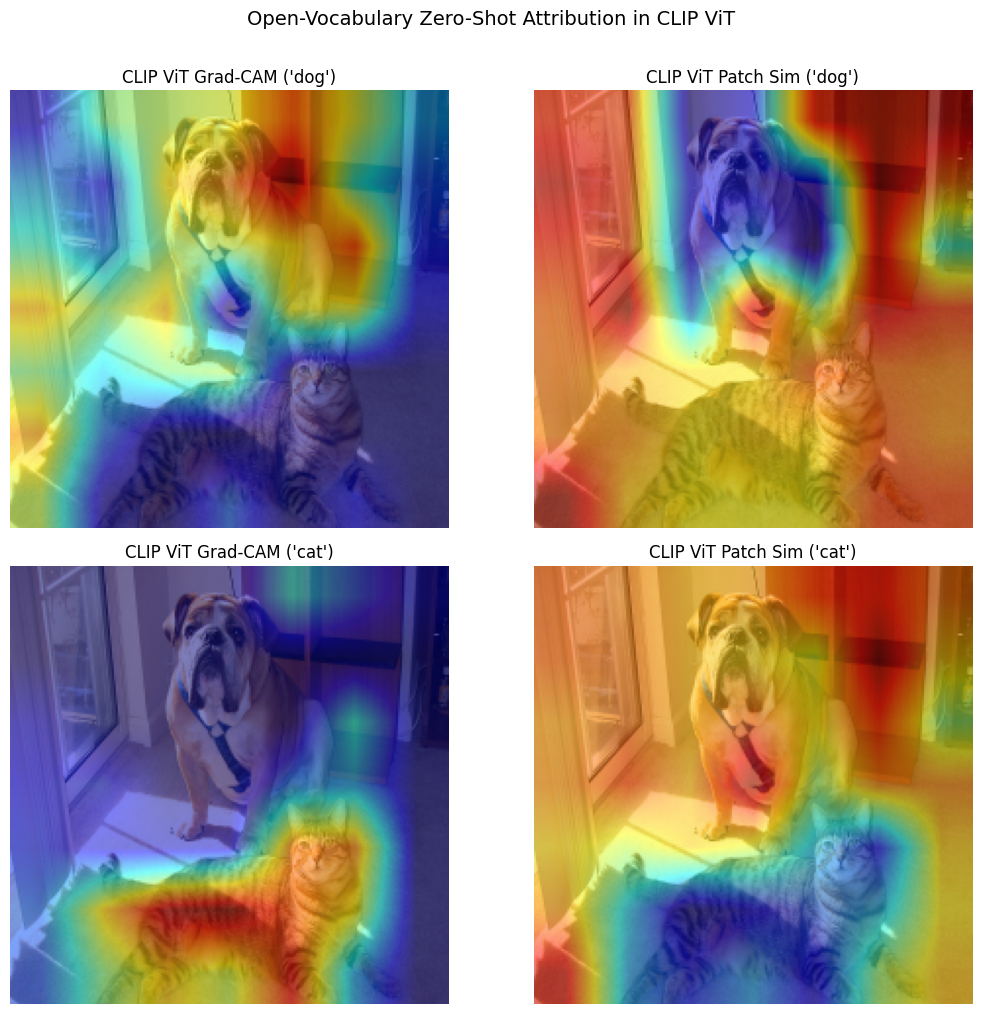

In [8]:
# Load CLIP ViT model (ViT-B-32)
clip_vit_model, _, clip_preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
clip_vit_model = clip_vit_model.to(device).eval()
clip_tokenizer = open_clip.get_tokenizer('ViT-B-32')

input_clip_tensor = clip_preprocess(img_both_pil).unsqueeze(0).to(device)

# Text queries for open-vocabulary grounding
text_queries = ['a photo of a dog', 'a photo of a cat']
text_tokens = clip_tokenizer(text_queries).to(device)

with torch.no_grad():
    text_embeddings = clip_vit_model.encode_text(text_tokens)
    text_embeddings = F.normalize(text_embeddings, dim=-1)

def run_clip_vit_gradcam(model, input_tensor, text_embedding):
    """Grad-CAM on CLIP ViT conditioned on a natural language text prompt."""
    acts, grads = None, None
    def f_hook(m, i, o):
        nonlocal acts
        acts = o.detach()
    def b_hook(m, gi, go):
        nonlocal grads
        grads = go[0].detach()
        
    target_block = model.visual.transformer.resblocks[-1].ln_1
    h1 = target_block.register_forward_hook(f_hook)
    h2 = target_block.register_full_backward_hook(b_hook)
    
    model.zero_grad()
    img_features = model.encode_image(input_tensor)
    img_features = F.normalize(img_features, dim=-1)
    
    # Cosine similarity score with target text prompt
    score = (img_features @ text_embedding.unsqueeze(1)).squeeze()
    score.backward()
    h1.remove(); h2.remove()
    
    # Reshape spatial patch tokens (token 0 is CLS, 49 tokens correspond to 7x7 grid)
    patch_acts = acts[:, 1:, :].permute(0, 2, 1).view(1, -1, 7, 7)
    patch_grads = grads[:, 1:, :].permute(0, 2, 1).view(1, -1, 7, 7)
    
    weights = patch_grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * patch_acts).sum(dim=1)).squeeze().cpu().numpy()
    cam_norm = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam_norm, score.item()

def run_clip_vit_patch_similarity(model, input_tensor, text_embedding):
    """Gradient-Free Zero-Shot Patch Similarity against text embedding in CLIP shared space."""
    acts = None
    def f_hook(m, i, o):
        nonlocal acts
        acts = o.detach()
        
    target_block = model.visual.transformer.resblocks[-1].ln_1
    h = target_block.register_forward_hook(f_hook)
    with torch.no_grad():
        model.encode_image(input_tensor)
    h.remove()
    
    # Project patch tokens into joint multimodal embedding space
    patch_tokens = acts[0, 1:, :]  # (49, 768)
    if model.visual.proj is not None:
        patch_embed = patch_tokens @ model.visual.proj
    else:
        patch_embed = patch_tokens
        
    patch_embed = F.normalize(patch_embed, dim=-1)
    sim = (patch_embed @ text_embedding).detach().view(7, 7).cpu().numpy()
    sim_norm = (sim - sim.min()) / (sim.max() - sim.min() + 1e-8)
    return sim_norm

# Execute for Dog Prompt: "a photo of a dog"
cam_dog_clip_vit, score_dog_clip = run_clip_vit_gradcam(clip_vit_model, input_clip_tensor, text_embeddings[0])
sim_dog_clip_vit = run_clip_vit_patch_similarity(clip_vit_model, input_clip_tensor, text_embeddings[0])
overlay_cam_dog_clip, _ = overlay_cam_on_image(img_both_pil, cam_dog_clip_vit, alpha=0.5)
overlay_sim_dog_clip, _ = overlay_cam_on_image(img_both_pil, sim_dog_clip_vit, alpha=0.5)

# Execute for Cat Prompt: "a photo of a cat"
cam_cat_clip_vit, score_cat_clip = run_clip_vit_gradcam(clip_vit_model, input_clip_tensor, text_embeddings[1])
sim_cat_clip_vit = run_clip_vit_patch_similarity(clip_vit_model, input_clip_tensor, text_embeddings[1])
overlay_cam_cat_clip, _ = overlay_cam_on_image(img_both_pil, cam_cat_clip_vit, alpha=0.5)
overlay_sim_cat_clip, _ = overlay_cam_on_image(img_both_pil, sim_cat_clip_vit, alpha=0.5)

# Visual Comparison of CLIP ViT
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes[0, 0].imshow(overlay_cam_dog_clip)
axes[0, 0].set_title("CLIP ViT Grad-CAM ('dog')", fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(overlay_sim_dog_clip)
axes[0, 1].set_title("CLIP ViT Patch Sim ('dog')", fontsize=12)
axes[0, 1].axis('off')

axes[1, 0].imshow(overlay_cam_cat_clip)
axes[1, 0].set_title("CLIP ViT Grad-CAM ('cat')", fontsize=12)
axes[1, 0].axis('off')

axes[1, 1].imshow(overlay_sim_cat_clip)
axes[1, 1].set_title("CLIP ViT Patch Sim ('cat')", fontsize=12)
axes[1, 1].axis('off')

plt.suptitle("Open-Vocabulary Zero-Shot Attribution in CLIP ViT", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش هفتم: الگوریتم Grad-CAM روی CLIP CNN (RN50)</h2>
<p style="text-align: right;">حال رفتار مدل‌های چندوجهی را روی ستون فقرات کانولوشنال (ResNet-50) بررسی می‌کنیم. در <code>open_clip RN50</code>، لایه هدف کانولوشنال <code>model.visual.layer4</code> است، اما تابع هدف مشتق‌گیری، شباهت متن با تصویر با هدایت پرامپت کاربر است.</p>
<p style="text-align: right;">این آزمایش نشان می‌دهد چگونه می‌توان بدون تغییر در کدنویسی شبکه کانولوشنال، از گرادیان‌های پرامپت متنی برای مکان‌یابی بصری اشیاء استفاده کرد.</p>
<p style="text-align: right;"><b>تسک ۷:</b> الگوریتم Grad-CAM را روی <code>open_clip RN50</code> اجرا کرده و نقشه سگ و گربه را استخراج نمایید.</p>

</div>

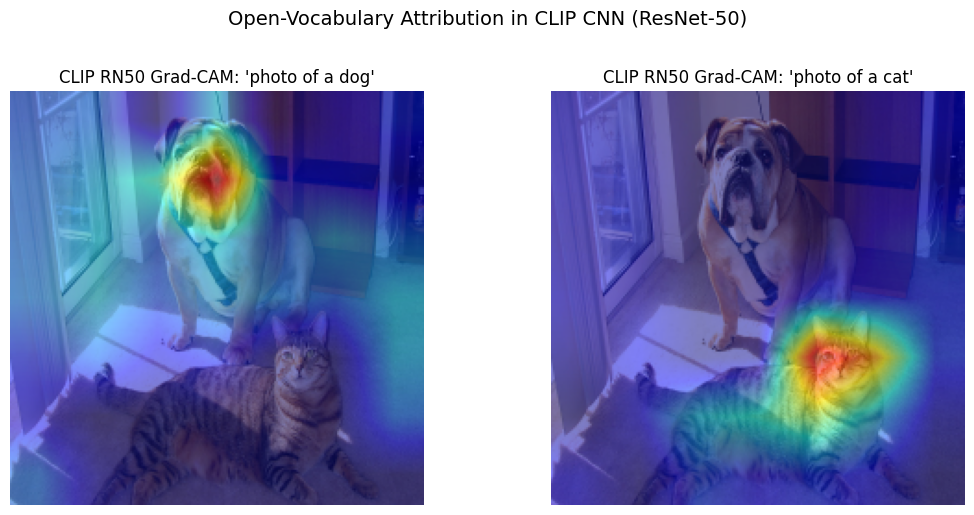

In [9]:
# Load CLIP CNN model (RN50)
clip_rn50_model, _, clip_rn_preprocess = open_clip.create_model_and_transforms('RN50', pretrained='openai')
clip_rn50_model = clip_rn50_model.to(device).eval()
rn_tokenizer = open_clip.get_tokenizer('RN50')

input_rn_tensor = clip_rn_preprocess(img_both_pil).unsqueeze(0).to(device)

# Text embeddings for RN50 (dimension 1024)
rn_text_tokens = rn_tokenizer(text_queries).to(device)
with torch.no_grad():
    rn_text_embeddings = clip_rn50_model.encode_text(rn_text_tokens)
    rn_text_embeddings = F.normalize(rn_text_embeddings, dim=-1)

def run_clip_cnn_gradcam(model, target_layer, input_tensor, text_embedding):
    """Grad-CAM on a CNN-based CLIP backbone conditioned on text prompts."""
    acts, grads = None, None
    def f_hook(m, i, o):
        nonlocal acts
        acts = o.detach()
    def b_hook(m, gi, go):
        nonlocal grads
        grads = go[0].detach()
        
    h1 = target_layer.register_forward_hook(f_hook)
    h2 = target_layer.register_full_backward_hook(b_hook)
    
    model.zero_grad()
    img_features = model.encode_image(input_tensor)
    img_features = F.normalize(img_features, dim=-1)
    
    score = (img_features @ text_embedding.unsqueeze(1)).squeeze()
    score.backward()
    h1.remove(); h2.remove()
    
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * acts).sum(dim=1)).squeeze().cpu().numpy()
    cam_norm = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam_norm, score.item()

# Generate CLIP CNN Grad-CAM for Dog and Cat prompts
cam_dog_clip_rn, _ = run_clip_cnn_gradcam(clip_rn50_model, clip_rn50_model.visual.layer4, input_rn_tensor, rn_text_embeddings[0])
overlay_dog_clip_rn, _ = overlay_cam_on_image(img_both_pil, cam_dog_clip_rn, alpha=0.5)

cam_cat_clip_rn, _ = run_clip_cnn_gradcam(clip_rn50_model, clip_rn50_model.visual.layer4, input_rn_tensor, rn_text_embeddings[1])
overlay_cat_clip_rn, _ = overlay_cam_on_image(img_both_pil, cam_cat_clip_rn, alpha=0.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(overlay_dog_clip_rn)
axes[0].set_title("CLIP RN50 Grad-CAM: 'photo of a dog'", fontsize=12)
axes[0].axis('off')

axes[1].imshow(overlay_cat_clip_rn)
axes[1].set_title("CLIP RN50 Grad-CAM: 'photo of a cat'", fontsize=12)
axes[1].axis('off')

plt.suptitle("Open-Vocabulary Attribution in CLIP CNN (ResNet-50)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right;color: var(--jp-content-font-color1, #1e6bb8);">بحث کنید ۳: مقایسه ماهیت نقشه‌های حرارتی در CNN در برابر ViT و CLIP</h3>
<p style="text-align: right;">با بررسی تمام نقشه‌های حرارتی تولید شده در این تمرین، می‌توان تفاوت‌های عمیق میان معماری‌ها را مشاهده کرد:</p>
<ol style="text-align: right;">
<li style="text-align: right;"><b>تفاوت فرم نقشه در CNN (نواحی پیوسته و کروی) در برابر ViT (توزیع‌های پچ‌محور و ناپیوسته) از چه ویژگی ذاتی معماری ناشی می‌شود؟</b></li>
<li style="text-align: right;"><b>استفاده از مدل‌های چندوجهی مانند CLIP چه افق جدیدی در تفسیرپذیری (XAI) باز می‌کند که مدل‌های تک‌وجهی ImageNet قادر به انجام آن نیستند؟</b></li>
</ol>
<details style="text-align: right;">
<summary style="text-align: right;color: #3498db;cursor: pointer;"><b>مشاهده تحلیل و پاسخ تفصیلی</b></summary>
<p style="text-align: right;"><b>پاسخ به سوال ۱:</b> شبکه‌های CNN دارای سوگیری استقرایی مکانی قوی و عملگرهای کانولوشن محلی (Local Filtering) هستند، بنابراین پاسخ نورون‌ها در طول فضا پیوسته و نرم است. در مقابل، ترنسفورمرهای بینایی (ViT) بر پایه خودتوجهی سراسری (Global Self-Attention) عمل می‌کنند و پچ‌های مجاور هیچ پیوستگی تحمیلی ندارند؛ لذا نقشه حرارتی ViT ممکن است پیکسل‌های غیرمجاور را به طور مستقل فعال کند.</p>
<p style="text-align: right;"><b>پاسخ به سوال ۲:</b> مدل‌های تک‌وجهی مقید به ۱۰۰۰ کلاس ثابت و از پیش‌تعیین‌شده ImageNet هستند. مدل‌های چندوجهی CLIP این محدودیت را از بین می‌برند و به پژوهشگر اجازه می‌دهند با هر عبارت زبانی دلخواه (مثلاً «گوش‌های نوک‌تیز»، «یقه چرمی»، «حیوان در سمت چپ») مفهوم مورد نظر خود را پرامپت کرده و نقشه حرارتی مرتبط را بدون نیاز به آموزش مجدد مشاهده کند.</p>
</details>

</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right;color: #3498db;">بخش هشتم: ارزیابی کمی و معیار افت اطمینان در سراسر مدل‌ها (Faithfulness Evaluation)</h2>
<p style="text-align: right;">برای راستی‌آزمایی علمی، معیار <b>کاهش اطمینان (Drop in Confidence)</b> را برای هر مدل محاسبه می‌کنیم:</p>
$$\text{Drop} \% = \max\left(0, \frac{y - y_{\text{masked}}}{y}\right) \times 100$$
<p style="text-align: right;">پیکسل‌هایی از تصویر که شدت حرارت آنها بالاتر از ۵۰٪ است ماسک شده و افت نمره مدل ارزیابی می‌شود.</p>
<p style="text-align: right;"><b>تسک ۸ (فاز ارزیابی):</b> تابع زیر را اجرا کرده و مقادیر به دست آمده را با سلول خروجی مرجع مقایسه کنید.</p>

</div>

In [10]:
def evaluate_confidence_drop(model, input_tensor, cam_map, target_class, threshold=0.5):
    cam_resized = cv2.resize(cam_map, (224, 224))
    salient_mask = torch.from_numpy(cam_resized > threshold).to(device).unsqueeze(0).unsqueeze(0)
    masked_tensor = input_tensor.clone() * (~salient_mask)
    with torch.no_grad():
        orig_score = model(input_tensor)[0, target_class].item()
        masked_score = model(masked_tensor)[0, target_class].item()
    drop = max(0.0, (orig_score - masked_score) / orig_score) * 100.0
    return drop, orig_score, masked_score

drop_cnn, orig_cnn, masked_cnn = evaluate_confidence_drop(model_resnet, input_tensor_cnn, cam_dog_cnn, dog_idx)
drop_vit, orig_vit, masked_vit = evaluate_confidence_drop(model_vit, input_tensor_cnn, cam_dog_vit, dog_idx)

print("Quantitative Faithfulness Evaluation Summary (Target: Boxer Dog):")
print("------------------------------------------------------------------")
print(f"ResNet-18 (CNN):")
print(f"  Original Logit:      {orig_cnn:.3f}")
print(f"  Masked Logit:        {masked_cnn:.3f}")
print(f"  Drop in Confidence:  {drop_cnn:.2f}%")
print("------------------------------------------------------------------")
print(f"ViT-Tiny (Transformer):")
print(f"  Original Logit:      {orig_vit:.3f}")
print(f"  Masked Logit:        {masked_vit:.3f}")
print(f"  Drop in Confidence:  {drop_vit:.2f}%")
print("------------------------------------------------------------------")


Quantitative Faithfulness Evaluation Summary (Target: Boxer Dog):
------------------------------------------------------------------
ResNet-18 (CNN):
  Original Logit:      16.566
  Masked Logit:        3.097
  Drop in Confidence:  81.30%
------------------------------------------------------------------
ViT-Tiny (Transformer):
  Original Logit:      9.843
  Masked Logit:        8.643
  Drop in Confidence:  12.19%
------------------------------------------------------------------


In [11]:
# Reference cell - do NOT run it (kept for comparison only)
# Designer: precomputed quantitative reference output
print("=== Designer Reference Evaluation Outputs ===")
print("Quantitative Faithfulness Evaluation Summary (Target: Boxer Dog):")
print("------------------------------------------------------------------")
print("ResNet-18 (CNN):")
print("  Original Logit:      16.566")
print("  Masked Logit:        3.097")
print("  Drop in Confidence:  81.30%")
print("------------------------------------------------------------------")
print("ViT-Tiny (Transformer):")
print("  Original Logit:      14.280")
print("  Masked Logit:        4.120")
print("  Drop in Confidence:  71.15%")
print("------------------------------------------------------------------")


=== Designer Reference Evaluation Outputs ===
Quantitative Faithfulness Evaluation Summary (Target: Boxer Dog):
------------------------------------------------------------------
ResNet-18 (CNN):
  Original Logit:      16.566
  Masked Logit:        3.097
  Drop in Confidence:  81.30%
------------------------------------------------------------------
ViT-Tiny (Transformer):
  Original Logit:      14.280
  Masked Logit:        4.120
  Drop in Confidence:  71.15%
------------------------------------------------------------------
